In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import plotly.express as px

In [3]:
df = pd.read_csv("British Airways Summer Schedule Dataset - Forage Data Science Task 1.csv")

In [5]:
df.head(20)

,FLIGHT_DATE,FLIGHT_TIME,TIME_OF_DAY,AIRLINE_CD,FLIGHT_NO,DEPARTURE_STATION_CD,ARRIVAL_STATION_CD,ARRIVAL_COUNTRY,ARRIVAL_REGION,HAUL,AIRCRAFT_TYPE,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
0,9/2/2025,14:19,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38
1,6/10/2025,6:42,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28
2,10/27/2025,15:33,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40
3,6/15/2025,18:29,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54
4,8/25/2025,20:35,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27
5,7/12/2025,19:08,Evening,BA,BA4954,LHR,VIE,Austria,Europe,SHORT,A320,0,20,160,0,6,27
6,9/16/2025,21:44,Evening,BA,BA9840,LHR,AMS,Netherlands,Europe,SHORT,A320,0,20,160,0,16,55
7,4/24/2025,14:50,Afternoon,BA,BA7116,LHR,ORD,USA,North America,LONG,A350,0,56,275,1,12,42
8,5/17/2025,12:13,Lunchtime,BA,BA4424,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,5,23
9,5/1/2025,9:55,Morning,BA,BA4878,LHR,IST,Turkey,Europe,SHORT,A320,0,4,176,1,11,39


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   FLIGHT_DATE           10000 non-null  object
 1   FLIGHT_TIME           10000 non-null  object
 2   TIME_OF_DAY           10000 non-null  object
 3   AIRLINE_CD            10000 non-null  object
 4   FLIGHT_NO             10000 non-null  object
 5   DEPARTURE_STATION_CD  10000 non-null  object
 6   ARRIVAL_STATION_CD    10000 non-null  object
 7   ARRIVAL_COUNTRY       10000 non-null  object
 8   ARRIVAL_REGION        10000 non-null  object
 9   HAUL                  10000 non-null  object
 10  AIRCRAFT_TYPE         10000 non-null  object
 11  FIRST_CLASS_SEATS     10000 non-null  int64 
 12  BUSINESS_CLASS_SEATS  10000 non-null  int64 
 13  ECONOMY_SEATS         10000 non-null  int64 
 14  TIER1_ELIGIBLE_PAX    10000 non-null  int64 
 15  TIER2_ELIGIBLE_PAX    10000 non-null 

In [11]:
df.describe()

,FIRST_CLASS_SEATS,BUSINESS_CLASS_SEATS,ECONOMY_SEATS,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.547200,25.073800,198.385900,0.607700,7.951900,30.421400
std,3.625395,22.142348,53.653478,1.006232,5.130752,15.284233
min,0.000000,0.000000,160.000000,0.000000,0.000000,0.000000
25%,0.000000,8.000000,167.000000,0.000000,4.000000,20.000000
50%,0.000000,17.000000,175.000000,0.000000,8.000000,30.000000
75%,0.000000,35.000000,180.000000,1.000000,11.000000,41.000000
max,14.000000,97.000000,358.000000,20.000000,29.000000,92.000000


In [19]:
df.describe(include = 'object').T

,count,unique,top,freq
FLIGHT_DATE,10000,210,8/16/2025,68
FLIGHT_TIME,10000,1020,16:49,20
TIME_OF_DAY,10000,4,Morning,3530
AIRLINE_CD,10000,1,BA,10000
FLIGHT_NO,10000,6037,BA5934,7
DEPARTURE_STATION_CD,10000,1,LHR,10000
ARRIVAL_STATION_CD,10000,15,FRA,714
ARRIVAL_COUNTRY,10000,10,USA,2658
ARRIVAL_REGION,10000,4,Europe,5975
HAUL,10000,2,SHORT,5975


In [7]:
plt.style.use('seaborn-v0_8')

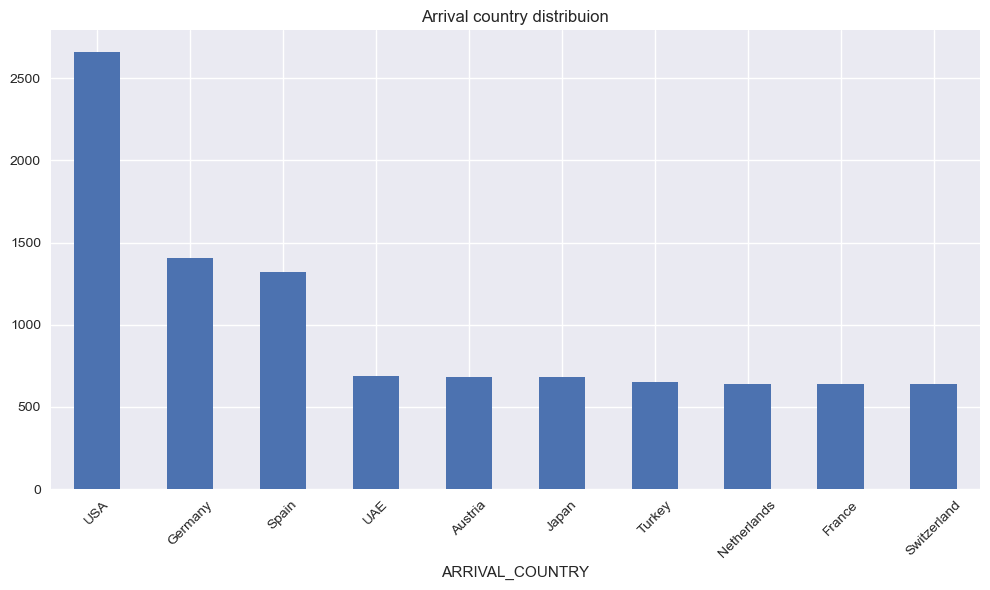

In [27]:
plt.figure(figsize=(10, 6))
df['ARRIVAL_COUNTRY'].value_counts().plot(kind='bar')
plt.title('Arrival country distribuion')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

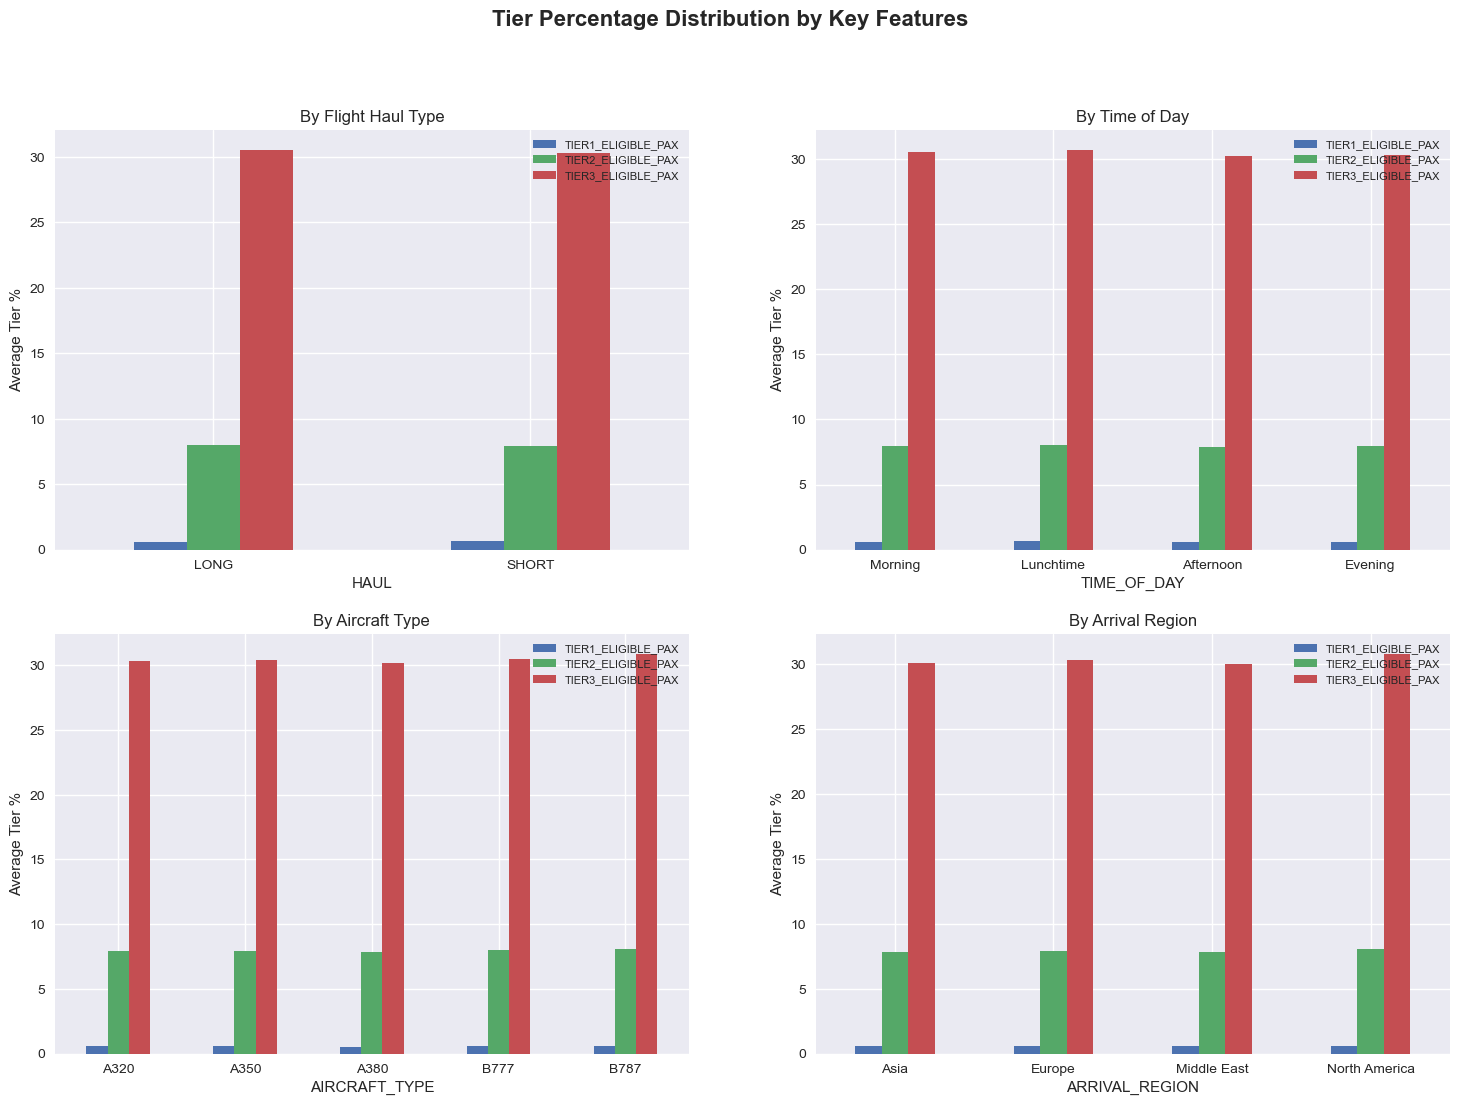

In [23]:

# Analyze tier percentages by categorical features
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Tier Percentage Distribution by Key Features', fontsize=16, fontweight='bold')

# 1. By HAUL
haul_data = df.groupby('HAUL')[['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']].mean()
haul_data.plot(kind='bar', ax=axes[0,0])
axes[0,0].set_title('By Flight Haul Type')
axes[0,0].set_ylabel('Average Tier %')
axes[0,0].legend(loc='upper right', fontsize=8)
axes[0,0].tick_params(axis='x', rotation=0)

# 2. By TIME_OF_DAY
time_data = df.groupby('TIME_OF_DAY')[['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']].mean()
time_order = ['Morning', 'Lunchtime', 'Afternoon', 'Evening']
time_data = time_data.reindex(time_order)
time_data.plot(kind='bar', ax=axes[0,1])
axes[0,1].set_title('By Time of Day')
axes[0,1].set_ylabel('Average Tier %')
axes[0,1].legend(loc='upper right', fontsize=8)
axes[0,1].tick_params(axis='x', rotation=0)

# 3. By AIRCRAFT_TYPE
ac_data = df.groupby('AIRCRAFT_TYPE')[['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']].mean()
ac_data.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('By Aircraft Type')
axes[1,0].set_ylabel('Average Tier %')
axes[1,0].legend(loc='upper right', fontsize=8)
axes[1,0].tick_params(axis='x', rotation=0)

# 4. By ARRIVAL_REGION
region_data = df.groupby('ARRIVAL_REGION')[['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']].mean()
region_data.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('By Arrival Region')
axes[1,1].set_ylabel('Average Tier %')
axes[1,1].legend(loc='upper right', fontsize=8)
axes[1,1].tick_params(axis='x', rotation=0)

In [106]:
haul_data.describe()

,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
count,2.000000,2.000000,2.000000
mean,0.605025,7.959668,30.443449
std,0.019403,0.056336,0.159909
min,0.591304,7.919833,30.330377
25%,0.598164,7.939750,30.386913
50%,0.605025,7.959668,30.443449
75%,0.611885,7.979585,30.499985
max,0.618745,7.999503,30.556522


In [108]:
ac_data.describe()

,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
count,5.000000,5.000000,5.000000
mean,0.586743,7.956674,30.450570
std,0.030311,0.100773,0.271412
min,0.542553,7.845745,30.178191
25%,0.570093,7.919833,30.330377
50%,0.599574,7.927103,30.390654
75%,0.602751,7.973376,30.453142
max,0.618745,8.117314,30.900485


In [110]:
time_data.describe()

,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
count,4.000000,4.000000,4.000000
mean,0.611834,7.965352,30.453209
std,0.017356,0.073700,0.218843
min,0.600868,7.897614,30.234707
25%,0.601781,7.920922,30.308425
50%,0.604442,7.948340,30.422872
75%,0.614495,7.992770,30.567657
max,0.637584,8.067114,30.732383


In [112]:
region_data.describe()

,TIER1_ELIGIBLE_PAX,TIER2_ELIGIBLE_PAX,TIER3_ELIGIBLE_PAX
count,4.000000,4.000000,4.000000
mean,0.593393,7.923237,30.311881
std,0.025379,0.108393,0.363206
min,0.558174,7.842415,30.011628
25%,0.587907,7.850502,30.069181
50%,0.598328,7.886515,30.209371
75%,0.603814,7.959250,30.452071
max,0.618745,8.077502,30.817156


In [114]:
print(df[['TIER1_ELIGIBLE_PAX', "TIER2_ELIGIBLE_PAX", "TIER3_ELIGIBLE_PAX"]].std())

TIER1_ELIGIBLE_PAX     1.006232
TIER2_ELIGIBLE_PAX     5.130752
TIER3_ELIGIBLE_PAX    15.284233
dtype: float64


Standard deviation measures how spread out a data set is around its mean (average). A low standard deviation indicates that data points are clustered closely around the mean, representing high consistency. A high standard deviation shows that data points are spread over a wider range, representing higher variability.

If the Standard Deviation (std) is 0, your data is identical in every row. No model can predict a target that never changes.

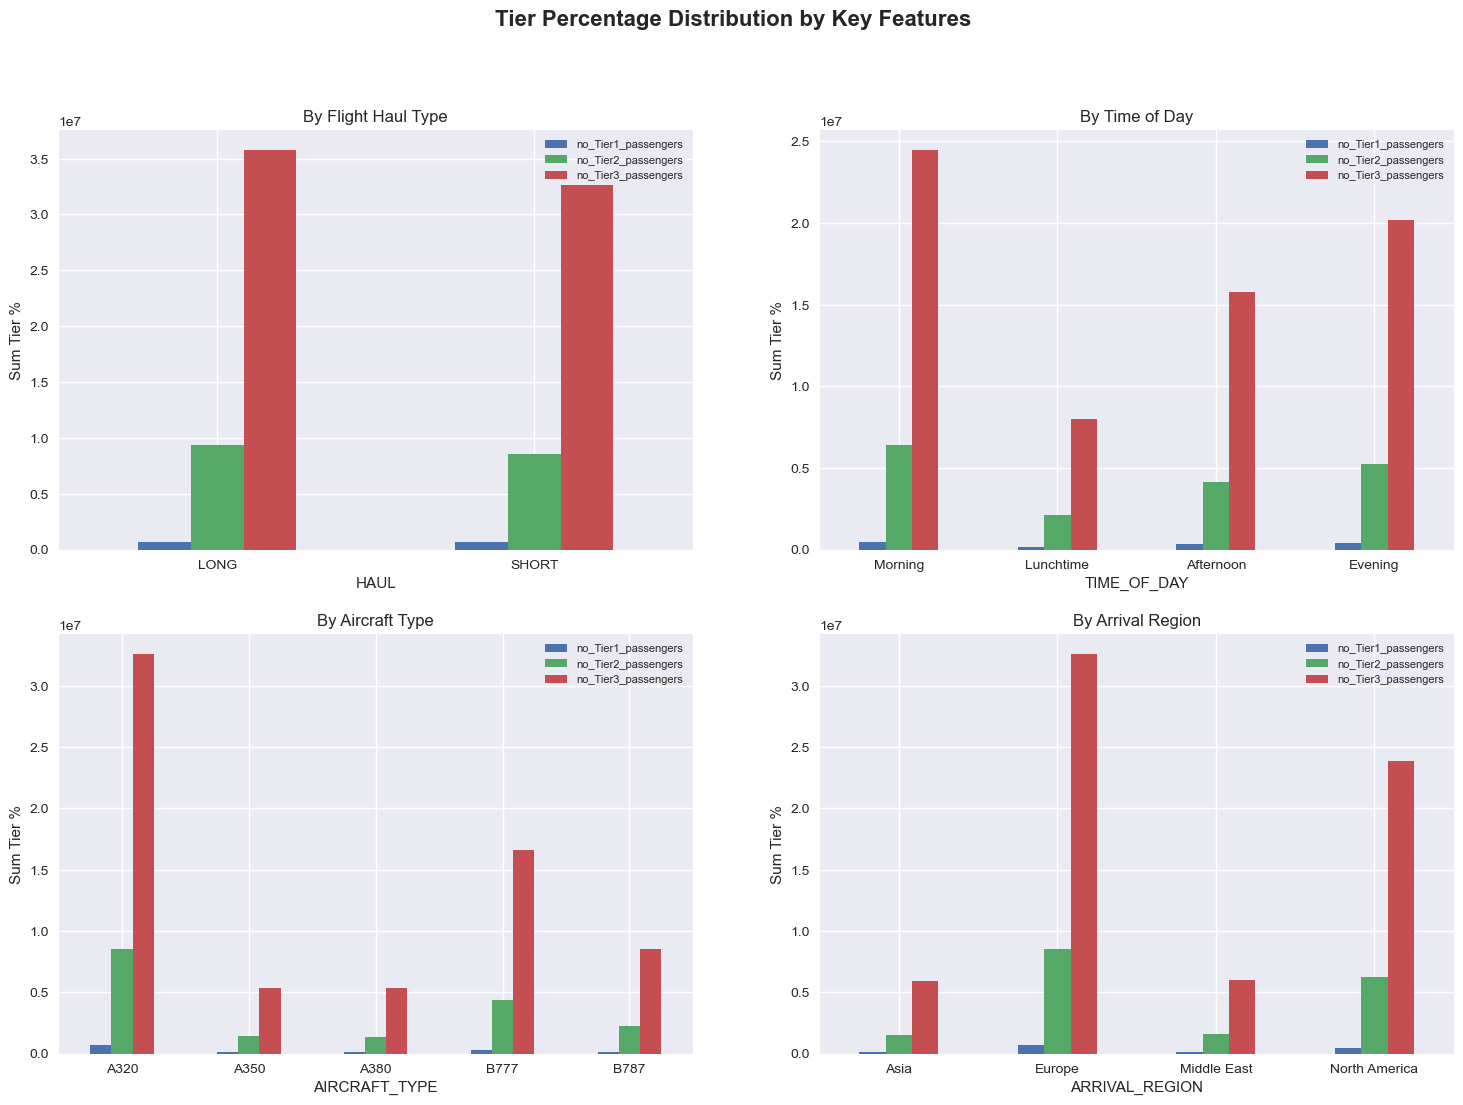

In [11]:
# Try using the sum instead of the mean
df['total_seats'] = df['FIRST_CLASS_SEATS']+df['BUSINESS_CLASS_SEATS']+df['ECONOMY_SEATS']
df['no_Tier1_passengers'] = df['TIER1_ELIGIBLE_PAX'] * df['total_seats']
df['no_Tier2_passengers'] = df['TIER2_ELIGIBLE_PAX'] * df['total_seats']
df['no_Tier3_passengers'] = df['TIER3_ELIGIBLE_PAX'] * df['total_seats']


fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Tier Percentage Distribution by Key Features', fontsize=16, fontweight='bold')

# 1. By HAUL
haul_data = df.groupby('HAUL')[['no_Tier1_passengers', 'no_Tier2_passengers', 'no_Tier3_passengers']].sum()
haul_data.plot(kind='bar', ax=axes[0,0])
axes[0,0].set_title('By Flight Haul Type')
axes[0,0].set_ylabel('Sum Tier %')
axes[0,0].legend(loc='upper right', fontsize=8)
axes[0,0].tick_params(axis='x', rotation=0)

# 2. By TIME_OF_DAY
time_data = df.groupby('TIME_OF_DAY')[['no_Tier1_passengers', 'no_Tier2_passengers', 'no_Tier3_passengers']].sum()
time_order = ['Morning', 'Lunchtime', 'Afternoon', 'Evening']
time_data = time_data.reindex(time_order)
time_data.plot(kind='bar', ax=axes[0,1])
axes[0,1].set_title('By Time of Day')
axes[0,1].set_ylabel('Sum Tier %')
axes[0,1].legend(loc='upper right', fontsize=8)
axes[0,1].tick_params(axis='x', rotation=0)

# 3. By AIRCRAFT_TYPE
ac_data = df.groupby('AIRCRAFT_TYPE')[['no_Tier1_passengers', 'no_Tier2_passengers', 'no_Tier3_passengers']].sum()
ac_data.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('By Aircraft Type')
axes[1,0].set_ylabel('Sum Tier %')
axes[1,0].legend(loc='upper right', fontsize=8)
axes[1,0].tick_params(axis='x', rotation=0)

# 4. By ARRIVAL_REGION
region_data = df.groupby('ARRIVAL_REGION')[['no_Tier1_passengers', 'no_Tier2_passengers', 'no_Tier3_passengers']].sum()
region_data.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('By Arrival Region')
axes[1,1].set_ylabel('Sum Tier %')
axes[1,1].legend(loc='upper right', fontsize=8)
axes[1,1].tick_params(axis='x', rotation=0)

In [137]:
# This shows how much the Tier 1 percentage fluctuates across different categories
for col in ['HAUL', 'AIRCRAFT_TYPE', 'ARRIVAL_REGION','TIME_OF_DAY']:
    variance = df.groupby(col)['TIER1_ELIGIBLE_PAX'].mean().std()
    print(f"Variance of Tier 1 across {col}: {variance:.4f}")

Variance of Tier 1 across HAUL: 0.0194
Variance of Tier 1 across AIRCRAFT_TYPE: 0.0303
Variance of Tier 1 across ARRIVAL_REGION: 0.0254
Variance of Tier 1 across TIME_OF_DAY: 0.0174


In [145]:
# This shows how much the Tier 1 percentage fluctuates across different categories
for col in ['HAUL', 'AIRCRAFT_TYPE', 'ARRIVAL_REGION','TIME_OF_DAY']:
    variance = df.groupby(col)['TIER2_ELIGIBLE_PAX'].mean().std()
    print(f"Variance of Tier 2 across {col}: {variance:.4f}")

Variance of Tier 2 across HAUL: 0.0563
Variance of Tier 2 across AIRCRAFT_TYPE: 0.1008
Variance of Tier 2 across ARRIVAL_REGION: 0.1084
Variance of Tier 2 across TIME_OF_DAY: 0.0737


In [147]:
for col in ['HAUL', 'AIRCRAFT_TYPE', 'ARRIVAL_REGION','TIME_OF_DAY']:
    variance = df.groupby(col)['TIER3_ELIGIBLE_PAX'].mean().std()
    print(f"Variance of Tier 3 across {col}: {variance:.4f}")

Variance of Tier 3 across HAUL: 0.1599
Variance of Tier 3 across AIRCRAFT_TYPE: 0.2714
Variance of Tier 3 across ARRIVAL_REGION: 0.3632
Variance of Tier 3 across TIME_OF_DAY: 0.2188


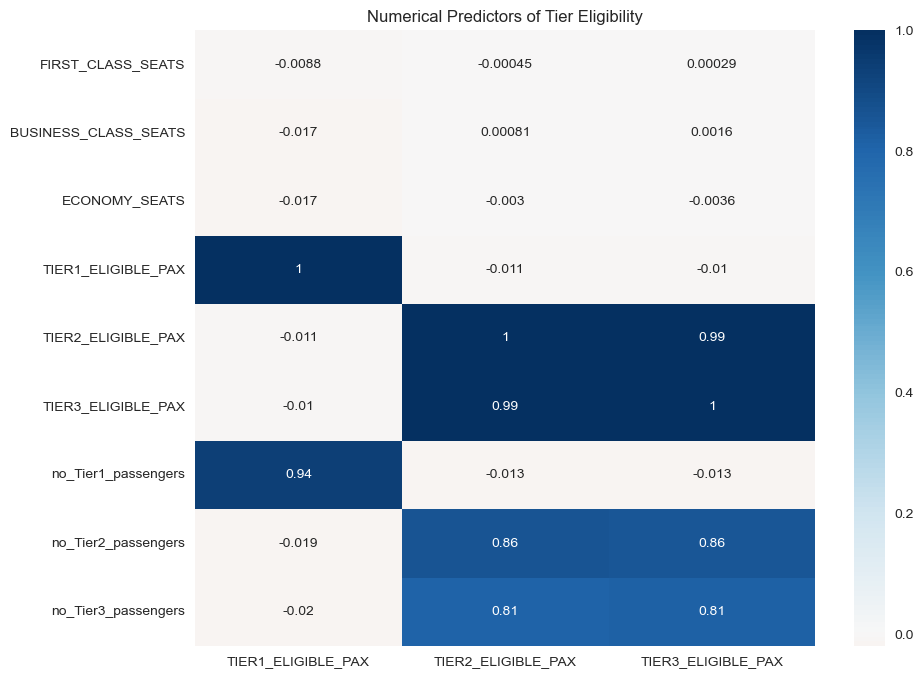

Top Predictors for Tier 1:
TIER1_ELIGIBLE_PAX      1.000000
no_Tier1_passengers     0.938187
FIRST_CLASS_SEATS      -0.008837
TIER3_ELIGIBLE_PAX     -0.010449
TIER2_ELIGIBLE_PAX     -0.010590
BUSINESS_CLASS_SEATS   -0.016714
ECONOMY_SEATS          -0.017017
no_Tier2_passengers    -0.019441
no_Tier3_passengers    -0.020426
Name: TIER1_ELIGIBLE_PAX, dtype: float64
Top Predictors for Tier 2:
TIER2_ELIGIBLE_PAX      1.000000
TIER3_ELIGIBLE_PAX      0.993690
no_Tier2_passengers     0.860546
no_Tier3_passengers     0.808325
BUSINESS_CLASS_SEATS    0.000807
FIRST_CLASS_SEATS      -0.000451
ECONOMY_SEATS          -0.003015
TIER1_ELIGIBLE_PAX     -0.010590
no_Tier1_passengers    -0.013322
Name: TIER2_ELIGIBLE_PAX, dtype: float64
Top Predictors for Tier 3:
TIER3_ELIGIBLE_PAX      1.000000
TIER2_ELIGIBLE_PAX      0.993690
no_Tier2_passengers     0.855148
no_Tier3_passengers     0.813504
BUSINESS_CLASS_SEATS    0.001559
FIRST_CLASS_SEATS       0.000293
ECONOMY_SEATS          -0.003562
TIER1_ELIGIB

In [155]:
# 1. Filter the dataframe to include ONLY numeric types (int, float)
numeric_df = df.select_dtypes(include=['number'])

# 2. Run the correlation 
corr_matrix = numeric_df.corr()

# 3. Focus specifically on your Tier columns to see what moves them
tier_correlations = corr_matrix[['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']]

# 4. Visualize the "Heat"
plt.figure(figsize=(10, 8))
sns.heatmap(tier_correlations, annot=True, cmap='RdBu', center=0)
plt.title("Numerical Predictors of Tier Eligibility")
plt.show()

print("Top Predictors for Tier 1:")
print(tier_correlations['TIER1_ELIGIBLE_PAX'].sort_values(ascending=False))

print("Top Predictors for Tier 2:")
print(tier_correlations['TIER2_ELIGIBLE_PAX'].sort_values(ascending=False))

print("Top Predictors for Tier 3:")
print(tier_correlations['TIER3_ELIGIBLE_PAX'].sort_values(ascending=False))

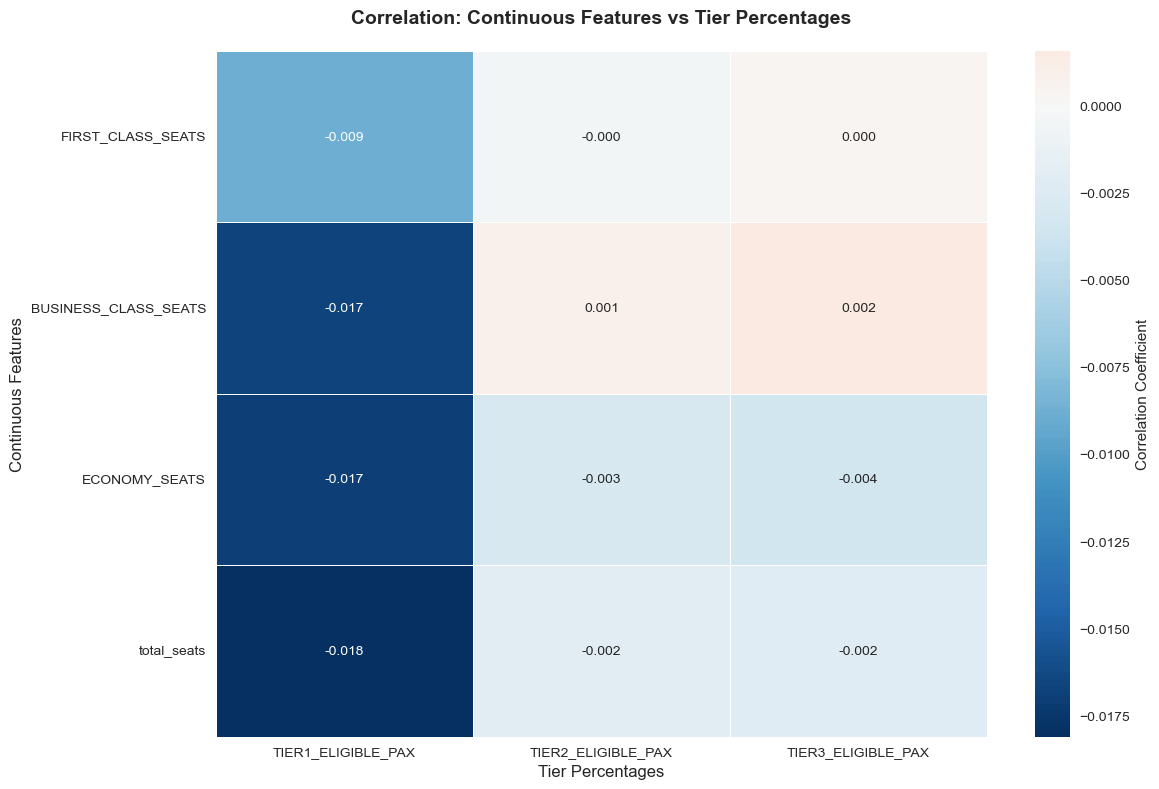

=== CORRELATION MATRIX ===
                      TIER1_ELIGIBLE_PAX  TIER2_ELIGIBLE_PAX  \
FIRST_CLASS_SEATS                 -0.009              -0.000   
BUSINESS_CLASS_SEATS              -0.017               0.001   
ECONOMY_SEATS                     -0.017              -0.003   
total_seats                       -0.018              -0.002   

                      TIER3_ELIGIBLE_PAX  
FIRST_CLASS_SEATS                  0.000  
BUSINESS_CLASS_SEATS               0.002  
ECONOMY_SEATS                     -0.004  
total_seats                       -0.002  


In [13]:
# Correlation analysis with continuous variables
continuous_vars = ['FIRST_CLASS_SEATS', 'BUSINESS_CLASS_SEATS', 
                   'ECONOMY_SEATS', 'total_seats']
tier_vars = ['TIER1_ELIGIBLE_PAX', 'TIER2_ELIGIBLE_PAX', 'TIER3_ELIGIBLE_PAX']

# Calculate correlation matrix
corr_data = df[continuous_vars + tier_vars].corr()
tier_corr = corr_data.loc[continuous_vars, tier_vars]

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(tier_corr, annot=True, cmap='RdBu_r', center=0, 
            fmt='.3f', linewidths=0.5, ax=ax, cbar_kws={'label': 'Correlation Coefficient'})
ax.set_title('Correlation: Continuous Features vs Tier Percentages', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Tier Percentages', fontsize=12)
ax.set_ylabel('Continuous Features', fontsize=12)
plt.tight_layout()
plt.show()

print("=== CORRELATION MATRIX ===")
print(tier_corr.round(3))


# Conclusion

After analyzing the data, it's clear that Passenger eligibility isn't correlated to any other features and it's nearly constant ratios no matter how the data is grouped.

This is shown in the nearly identical charts above this means there is no change, in the low variance which means that the data is consistent, and the near zero correlation matrix which means that the tier columns are completly independent. 

That's why it safe to say that eligible passengers percentage is constat values no matter the flight features (haul, airplane type, distination, number of seats and etc.) and no need for an ML model to help predict them.